# Lab 10 · Classical shadows

**Level 7 · Quantum Causal AI research** · Prerequisite lessons: L5-09 (Entropy and quantum tomography), L7-06 (Sample complexity and resource accounting), L7-07 (Classical shadows and observable structure).

**What you'll learn**

- How random Pauli measurements produce a classical shadow: a cheap classical record from which you can later estimate many expectation values [@shadows].
- Why the single-shot estimator for a weight-$k$ Pauli observable has variance $3^k-\langle P\rangle^2$. Local observables are therefore cheap, and global ones are expensive.
- How the estimation error falls like $1/\sqrt N$, and what median-of-means does.

:::{important} Scope
Classical shadows are a tool for *learning about* quantum states from measurements. They belong with quantum learning and estimation, not with quantum causal models or indefinite causal order. Everything here is simulated on a classical computer.
:::

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/10-classical-shadows.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math, itertools
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from qcai import science as s
from qcai.viz import show

np.set_printoptions(precision=4, suppress=True)
PAULI = (s.X, s.Y, s.Z)

## 1 · One qubit: estimate $\langle X\rangle,\langle Y\rangle,\langle Z\rangle$ from the same shots

In each shot, pick a basis $X$, $Y$, or $Z$ uniformly at random, measure, and record the outcome $b=\pm1$. The single-shot estimator of $\langle P\rangle$ is

$$
\hat o_P = 3\,b\cdot\mathbb 1[\text{basis}=P].
$$

It is unbiased: $\mathbb E[\hat o_P]=\tfrac13\cdot3\,\langle P\rangle=\langle P\rangle$. The engine's `classical_shadow_z` implements this for $Z$. Below we write a three-observable version that consumes the random numbers in the same order. We then check that its $Z$ estimate is *identical* to the engine's.

:::{note} Predict
The estimator for $\langle Z\rangle$ throws away the two-thirds of shots measured in $X$ or $Y$. Why is it still useful to measure randomly instead of always measuring $Z$?
:::

In [3]:
def shadow_xyz(rho, shots, seed=7):
    """Running means of the X, Y, Z shadow estimators (same RNG sequence as s.classical_shadow_z)."""
    g = np.random.default_rng(seed)
    est = np.zeros((shots, 3))
    for k in range(shots):
        idx = g.integers(3)
        p_plus = float(np.real(np.trace(rho @ (s.I2 + PAULI[idx]) / 2)))
        b = 1 if g.random() < p_plus else -1
        est[k, idx] = 3 * b
    return np.cumsum(est, axis=0) / np.arange(1, shots + 1)[:, None], est

rho1 = s.dm(s.ket(1.1, 0.6))
truth = s.bloch(rho1)
shots = 5000
running, single = shadow_xyz(rho1, shots, seed=7)
engine = s.classical_shadow_z(rho1, shots, seed=7)
assert np.allclose(running[:, 2], engine.estimates) and abs(engine.truth - truth[2]) < 1e-12
print("truth  <X>,<Y>,<Z> =", truth)
print("shadow estimates    =", running[-1], f"after {shots} shots")
# single-shot variance: E[o^2] = 9 * 1/3 = 3, so Var = 3 - <P>^2
emp_var = single.var(axis=0)
print("empirical single-shot variances:", emp_var, " theory 3 - <P>^2:", 3 - truth ** 2)
assert np.allclose(emp_var, 3 - truth ** 2, rtol=0.08)
assert np.all(np.abs(running[-1] - truth) < 4 * np.sqrt(3 / shots))

ns = np.unique(np.round(np.logspace(0, math.log10(shots), 200)).astype(int)) - 1
cols = ["#4c78a8", "#59a14f", "crimson"]
fig = go.Figure()
for i, lab in enumerate("XYZ"):
    fig.add_trace(go.Scatter(x=ns + 1, y=running[ns, i], mode="lines", name=f"estimate ⟨{lab}⟩", line=dict(color=cols[i])))
    fig.add_trace(go.Scatter(x=[1, shots], y=[truth[i]] * 2, mode="lines", name=f"true ⟨{lab}⟩",
                             line=dict(color=cols[i], dash="dot")))
vis = lambda i: [j // 2 == i for j in range(6)]
fig.update_layout(height=470, title="One set of random-Pauli shots, three observables", xaxis_type="log",
                  xaxis_title="number of shots", yaxis_title="estimate", yaxis_range=[-1.6, 1.6],
                  updatemenus=[dict(type="buttons", direction="right", x=0, y=1.13, xanchor="left", buttons=
                                    [dict(label="all", method="restyle", args=[{"visible": [True] * 6}])] +
                                    [dict(label=f"⟨{lab}⟩", method="restyle", args=[{"visible": vis(i)}]) for i, lab in enumerate("XYZ")])])
show(fig)

truth  <X>,<Y>,<Z> = [0.7355 0.5032 0.4536]
shadow estimates    = [0.72   0.525  0.4698] after 5000 shots
empirical single-shot variances: [2.394  2.7574 2.8339]  theory 3 - <P>^2: [2.459  2.7468 2.7943]


**Explain.** The same random record estimates all three expectation values. You could even choose the observables *after* collecting the data. Measuring only $Z$ would give $\langle Z\rangle$ with variance $1-\langle Z\rangle^2$ instead of $3-\langle Z\rangle^2$. But it would say nothing about $\langle X\rangle$ or $\langle Y\rangle$. The factor 3 is the price of not committing in advance.

## 2 · Several qubits and the $3^k$ cost

On $n$ qubits, each shot measures every qubit in an independently random Pauli basis. Take a Pauli string $P$ that acts non-trivially on a set $S$ of $k$ qubits (its weight). Then

$$
\hat o_P=\prod_{j\in S}3\,b_j\,\mathbb 1[\text{basis}_j=P_j] .
$$

All $k$ bases must match, which happens with probability $3^{-k}$. When they do, the estimator is $\pm3^k$. So $\mathbb E[\hat o_P^2]=3^k$ and $\operatorname{Var}\hat o_P=3^k-\langle P\rangle^2$. The code checks unbiasedness and this second moment exactly. It sums over all $3^n$ basis choices and $2^n$ outcomes, for every one of the $4^n-1$ non-identity Pauli strings of a random 4-qubit state.

In [4]:
n = 4
g = np.random.default_rng(2024)
psi = g.normal(size=2 ** n) + 1j * g.normal(size=2 ** n); psi /= np.linalg.norm(psi)
rho = s.dm(psi)

SDG = np.diag([1, -1j])
ROT = (s.H, s.H @ SDG, s.I2)            # rotate the X, Y, Z eigenbasis onto the computational basis
settings = list(itertools.product(range(3), repeat=n))
probs = np.array([np.abs(s.kron(*[ROT[b] for b in st]) @ psi) ** 2 for st in settings])     # (3^n, 2^n)
assert np.allclose(probs.sum(axis=1), 1)
bits = np.array(list(itertools.product([0, 1], repeat=n)))       # outcome index -> bits (qubit 0 first)
signs = 1 - 2 * bits                                             # b_j = +1 for bit 0, -1 for bit 1

def pauli_op(word):
    return s.kron(*[[s.I2, s.X, s.Y, s.Z][c] for c in word])

def single_shot_values(word, setting_idx, outcome_idx):
    """Estimator value for Pauli word (0=I,1=X,2=Y,3=Z per qubit), vectorized over shots."""
    val = np.ones(len(setting_idx))
    st = np.array(settings)[setting_idx]
    for j, c in enumerate(word):
        if c:
            val *= 3 * signs[outcome_idx, j] * (st[:, j] == c - 1)
    return val

S_idx, O_idx = np.meshgrid(np.arange(3 ** n), np.arange(2 ** n), indexing="ij")
weight_prob = probs / 3 ** n                     # joint probability of (setting, outcome)
words = [w for w in itertools.product(range(4), repeat=n) if any(w)]
for w in words:
    v = single_shot_values(w, S_idx.ravel(), O_idx.ravel()).reshape(3 ** n, 2 ** n)
    mean = np.sum(weight_prob * v); second = np.sum(weight_prob * v ** 2)
    k = sum(1 for c in w if c)
    assert abs(mean - np.real(np.trace(rho @ pauli_op(w)))) < 1e-12        # unbiased
    assert abs(second - 3 ** k) < 1e-9                                       # E[o^2] = 3^k
print(f"exact unbiasedness and E[o^2] = 3^k verified for all {len(words)} Pauli strings on {n} qubits")

exact unbiasedness and E[o^2] = 3^k verified for all 255 Pauli strings on 4 qubits


:::{note} Predict
At a fixed number of shots, how much larger should the error be for a weight-4 observable than for a weight-1 observable?
:::

Now we sample. We draw 200 independent experiments of up to 20 000 shots each. For one observable of each weight $k=1,\dots,4$, we compute the root-mean-square error. The dotted lines are the exact predictions $\sqrt{(3^k-\langle P\rangle^2)/N}$. Use the buttons to show one weight at a time.

In [5]:
R, Nmax = 200, 20000
gs = np.random.default_rng(99)
setting_draw = gs.integers(3 ** n, size=(R, Nmax))
cum = np.cumsum(probs, axis=1)
u = gs.random(size=(R, Nmax))
outcome_draw = np.empty((R, Nmax), dtype=np.int64)
for r in range(R):   # row by row to keep memory small
    outcome_draw[r] = np.minimum((u[r, :, None] > cum[setting_draw[r]]).sum(axis=-1), 2 ** n - 1)

chosen = {1: (0, 0, 3, 0), 2: (1, 0, 0, 1), 3: (3, 2, 0, 1), 4: (1, 3, 2, 3)}
Ns = np.unique(np.round(np.logspace(1.5, math.log10(Nmax), 12)).astype(int))
rmse, theory, truthP = {}, {}, {}
for k, w in chosen.items():
    truthP[k] = float(np.real(np.trace(rho @ pauli_op(w))))
    vals = single_shot_values(w, setting_draw.ravel(), outcome_draw.ravel()).reshape(R, Nmax)
    csum = np.cumsum(vals, axis=1)
    rmse[k] = np.array([math.sqrt(np.mean((csum[:, N - 1] / N - truthP[k]) ** 2)) for N in Ns])
    theory[k] = np.sqrt((3 ** k - truthP[k] ** 2) / Ns)
    assert np.all(np.abs(rmse[k] / theory[k] - 1) < 0.3)                  # matches theory within sampling error
    slope = np.polyfit(np.log(Ns), np.log(rmse[k]), 1)[0]
    assert abs(slope + 0.5) < 0.1                                         # 1/sqrt(N) scaling
    print(f"weight {k}: <P> = {truthP[k]:+.3f}, fitted log-log slope {slope:.3f}, RMSE at N={Ns[-1]}: {rmse[k][-1]:.4f}")
ratio = rmse[4][-1] / rmse[1][-1]
print(f"RMSE ratio weight-4 / weight-1 at N = {Ns[-1]}: {ratio:.2f}  (theory {theory[4][-1] / theory[1][-1]:.2f})")
assert abs(ratio / (theory[4][-1] / theory[1][-1]) - 1) < 0.3

colors = {1: "#4c78a8", 2: "#59a14f", 3: "#f28e2b", 4: "crimson"}
fig = go.Figure()
for k in chosen:
    fig.add_trace(go.Scatter(x=Ns, y=rmse[k], mode="markers+lines", name=f"weight {k} (simulated)", line=dict(color=colors[k])))
    fig.add_trace(go.Scatter(x=Ns, y=theory[k], mode="lines", name=f"weight {k} theory √((3^{k}−⟨P⟩²)/N)",
                             line=dict(color=colors[k], dash="dot")))
buttons = [dict(label="all", method="restyle", args=[{"visible": [True] * 8}])]
buttons += [dict(label=f"k = {k}", method="restyle", args=[{"visible": [j // 2 == k - 1 for j in range(8)]}]) for k in chosen]
fig.update_layout(height=500, title=f"Shadow estimation error vs shots ({n} qubits, {R} repetitions)", xaxis_type="log",
                  yaxis_type="log", xaxis_title="shots N", yaxis_title="RMSE",
                  updatemenus=[dict(type="buttons", direction="right", x=0, y=1.13, xanchor="left", buttons=buttons)])
show(fig)

weight 1: <P> = +0.411, fitted log-log slope -0.494, RMSE at N=20000: 0.0126
weight 2: <P> = +0.135, fitted log-log slope -0.497, RMSE at N=20000: 0.0222


weight 3: <P> = +0.015, fitted log-log slope -0.537, RMSE at N=20000: 0.0332
weight 4: <P> = +0.003, fitted log-log slope -0.486, RMSE at N=20000: 0.0645
RMSE ratio weight-4 / weight-1 at N = 20000: 5.13  (theory 5.35)


**Explain.** Every curve has slope $-1/2$ on the log-log plot, so the error falls like $1/\sqrt N$. The vertical offset grows with the weight, because the variance is $3^k-\langle P\rangle^2$. With random single-qubit Pauli measurements, low-weight (local) observables are cheap and high-weight ones become expensive. Huang, Kueng, and Preskill show a more general result [@shadows]. Order $\log M$ measurements suffice to predict $M$ properties when each has a bounded shadow norm, and the number of measurements needed does not grow with system size. For random Pauli measurements, the weight-$k$ cost computed here is what enters that bound.

## 3 · Many observables at once, and median-of-means

The same shots estimate *all* Pauli strings. A worst case over many observables is governed by the rare large deviations of each estimator. Median-of-means splits the $N$ shots into $K$ groups and averages within each group. It then reports the median of the $K$ group means. Huang, Kueng, and Preskill use this device to obtain their logarithmic dependence on the number of observables [@shadows].

Below we take every Pauli string of weight $\le 2$ (there are $\binom41 3+\binom42 9=66$). In each of the 200 experiments, we record the *largest* error across these observables. We do this with the plain mean and with median-of-means using $K=10$ groups.

N = 2000: worst error over 66 observables
  plain mean       : median 0.1680, 95th percentile 0.2150
  median-of-means  : median 0.1984, 95th percentile 0.2785


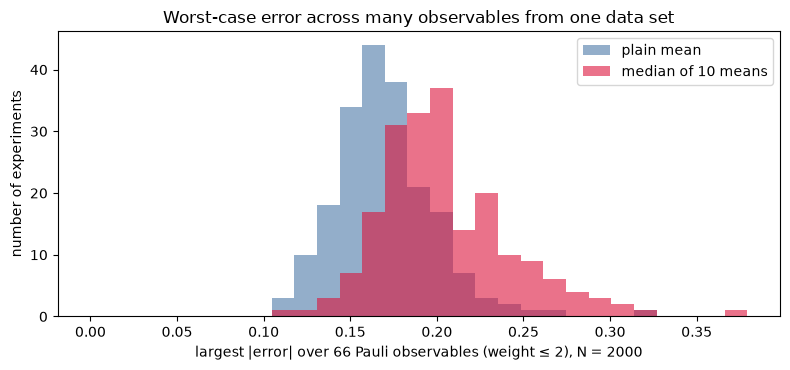

In [6]:
low = [w for w in words if sum(1 for c in w if c) <= 2]
assert len(low) == 4 * 3 + 6 * 9 == 66
N, K = 2000, 10
max_err_mean, max_err_mom = np.zeros(R), np.zeros(R)
for w in low:
    t = float(np.real(np.trace(rho @ pauli_op(w))))
    vals = single_shot_values(w, setting_draw[:, :N].ravel(), outcome_draw[:, :N].ravel()).reshape(R, N)
    mean_est = vals.mean(axis=1)
    mom_est = np.median(vals.reshape(R, K, N // K).mean(axis=2), axis=1)
    max_err_mean = np.maximum(max_err_mean, np.abs(mean_est - t))
    max_err_mom = np.maximum(max_err_mom, np.abs(mom_est - t))
q_mean, q_mom = np.quantile(max_err_mean, [0.5, 0.95]), np.quantile(max_err_mom, [0.5, 0.95])
print(f"N = {N}: worst error over {len(low)} observables")
print(f"  plain mean       : median {q_mean[0]:.4f}, 95th percentile {q_mean[1]:.4f}")
print(f"  median-of-means  : median {q_mom[0]:.4f}, 95th percentile {q_mom[1]:.4f}")
assert q_mean[1] < 0.3 and q_mom[1] < 0.3                     # both estimate all 66 observables to within 0.3 in 95% of runs
assert q_mom[1] > q_mean[1]                                    # in this simulation, median-of-means did NOT help

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(0, max(max_err_mean.max(), max_err_mom.max()), 30)
ax.hist(max_err_mean, bins=bins, alpha=0.6, label="plain mean", color="#4c78a8")
ax.hist(max_err_mom, bins=bins, alpha=0.6, label=f"median of {K} means", color="crimson")
ax.set_xlabel(f"largest |error| over {len(low)} Pauli observables (weight ≤ 2), N = {N}")
ax.set_ylabel("number of experiments"); ax.legend()
ax.set_title("Worst-case error across many observables from one data set")
plt.tight_layout(); plt.show()

**Explain.** One data set of $N=2000$ shots estimates all 66 low-weight Pauli expectation values at once. The code asserts that the worst of the 66 errors stays below $0.3$ in 95% of experiments for both estimators.

In this simulation median-of-means did not help. Its worst-case errors were somewhat larger than those of the plain mean (see the printed quantiles; the code asserts the direction). The estimators here are bounded (at most $\pm 9$ for weight 2), and each group holds only $N/K=200$ shots. So the median of a few noisy group means loses efficiency. What median-of-means offers is a *provable* exponential tail bound that needs only a finite variance. That matters when the number of observables is very large or the estimators are heavy-tailed, not necessarily at this scale.

## Going deeper: why "$3\,|b\rangle\langle b| - I$"?

Take a single random-Pauli measurement on one qubit. Averaged over the random basis $U$ and outcome $b$, it implements the channel $\mathcal M(\rho)=\mathbb E\big[U^\dagger|b\rangle\langle b|U\big]=\tfrac13\rho+\tfrac13 I$ (for $\operatorname{Tr}\rho=1$). Inverting this channel gives the snapshot $\hat\rho=\mathcal M^{-1}\big(U^\dagger|b\rangle\langle b|U\big)=3\,U^\dagger|b\rangle\langle b|U-I$, with $\mathbb E[\hat\rho]=\rho$. Then $\operatorname{Tr}(P\hat\rho)$ is exactly the estimator $\hat o_P$ used above. Snapshots are not physical states; they have a negative eigenvalue. Only their *average* is a state.

In [7]:
rho_t = s.dm(s.ket(0.8, 2.0))
avg_meas, avg_snap = np.zeros((2, 2), complex), np.zeros((2, 2), complex)
for b_idx, P in enumerate(PAULI):
    U = ROT[b_idx]
    for outcome in (0, 1):
        ket_b = U.conj().T @ np.eye(2)[outcome]
        prob = float(np.real(ket_b.conj() @ rho_t @ ket_b)) / 3
        snap = 3 * s.dm(ket_b) - s.I2
        avg_meas += prob * s.dm(ket_b)
        avg_snap += prob * snap
        assert np.linalg.eigvalsh(snap).min() < -0.99                         # eigenvalues are 2 and -1
        for Q in PAULI:   # Tr(Q snap) = 3b if Q is the measured Pauli, else 0
            expect = 3 * (1 - 2 * outcome) if Q is P else 0.0
            assert abs(np.real(np.trace(Q @ snap)) - expect) < 1e-12
assert np.allclose(avg_meas, rho_t / 3 + s.I2 / 3)
assert np.allclose(avg_snap, rho_t)
print("measurement channel M(rho) = rho/3 + I/3 and E[snapshot] = rho verified exactly")

measurement channel M(rho) = rho/3 + I/3 and E[snapshot] = rho verified exactly


## Exercises

:::{admonition} Exercise: :label: lab10-ex1
:class: tip
For a single qubit with $\langle Z\rangle=0.6$, compute the single-shot variance of the shadow estimator of $\langle Z\rangle$, and the number of shots for a standard error of $0.01$.
:::

:::{dropdown} Solution
$\operatorname{Var}=3-0.36=2.64$. Standard error $\sqrt{2.64/N}\le0.01$ requires $N\ge 26\,400$. Measuring $Z$ directly would need $N\ge(1-0.36)/10^{-4}=6400$.
:::

:::{admonition} Exercise: :label: lab10-ex2
:class: tip
On 10 qubits, how many Pauli strings have weight exactly 2? With random-Pauli shadows, what is the worst-case single-shot variance for any one of them?
:::

:::{dropdown} Solution
$\binom{10}{2}\cdot3^2=405$ strings. Each has variance $3^2-\langle P\rangle^2\le 9$, regardless of the number of qubits.
:::

:::{admonition} Exercise: :label: lab10-ex3
:class: tip
Why does the estimator for a weight-$n$ observable on $n$ qubits become useless for large $n$?
:::

:::{dropdown} Solution
Its variance is $3^n-\langle P\rangle^2$, so the number of shots for fixed precision grows like $3^n$. Only a fraction $3^{-n}$ of shots have all bases matching. Global observables, such as fidelity with an entangled state, need other measurement ensembles. The cited work uses random Clifford measurements for this.
:::

## Check yourself

In [8]:
var1 = 3 - 0.6 ** 2
assert abs(var1 - 2.64) < 1e-12 and math.ceil(var1 / 0.01 ** 2 - 1e-9) == 26400
assert math.ceil((1 - 0.36) / 0.01 ** 2 - 1e-9) == 6400
assert math.comb(10, 2) * 3 ** 2 == 405
assert sum(1 for w in words if sum(1 for c in w if c) == n) == 3 ** n     # weight-n strings on n qubits
print("All checks passed.")

All checks passed.


## Limits of this model

The systems are small. Four qubits allow exact checks, but shadows are meant for large systems, where exact simulation is impossible.

The measurements are perfect. Readout and gate errors bias the snapshots unless they are characterized and inverted.

We used only the Pauli ensemble. Random Clifford measurements change which observables are cheap. We did not simulate them.

The randomness is seeded. Basis choices and outcomes come from a fixed seed, so the page is reproducible. Real experiments need genuinely independent basis choices.

We make no advantage claim. For many properties, classical shadows reduce measurement cost relative to full tomography. This lab claims nothing beyond what the cited paper proves.